# Training ASL 24 Huruf: HOG + Gabor + PCA + LDA + k-NN

**Cukup jalankan notebook ini: Runtime → Run all.** Tidak perlu upload file Python lain. Gunakan Runtime **CPU** (tidak perlu GPU). Perkiraan waktu total 10–25 menit.

## Kombinasi metode (berbeda dari 4 kombinasi yang dilarang)

| Tahap | Metode |
|---|---|
| Pra pengolahan | grayscale → resize 64×64 → normalisasi 0–1 |
| Ekstraksi fitur | **HOG** + **Gabor filter bank** (energi 8 filter, dipool 4×4) → 1.892 fitur |
| Reduksi dimensi | StandardScaler → **PCA** → (opsional) **LDA** sebagai proyeksi terawasi |
| Klasifikasi | **k-NN**, **Logistic Regression**, **HistGradientBoosting**, atau LDA langsung |

Tidak memakai SVM, Random Forest, LBP, Hu Moments, kontur, maupun MediaPipe. Tujuh kandidat dibandingkan di validation, lalu dua terbaik diuji ulang dengan augmentasi. Pemenang dipilih otomatis, dan **official test baru diprediksi setelah pemenang dikunci**.

## Pembagian data yang lebih ketat
Sign Language MNIST dibuat dari foto asli yang diperbanyak, sehingga gambar yang hampir sama bisa masuk ke train dan validation sekaligus. Itu membuat validation terlalu mudah (pada percobaan SVM sebelumnya semua kandidat mendapat 100%). Di sini gambar yang mirip secara visual dikelompokkan dengan KMeans per huruf, lalu `StratifiedGroupKFold` memastikan satu kelompok tidak terpisah antara train dan validation. Ini **heuristik**, bukan jaminan bahwa tidak ada kebocoran.

## Hasil
Semua angka akurasi, presisi, recall, dan F1 dihasilkan saat notebook dijalankan. Tidak ada angka yang dijanjikan di sini. J dan Z tidak termasuk karena butuh gerakan. Ini eksperimen pada dataset 28×28, belum membuktikan akurasi pada foto kamera.

Output tersimpan di Google Drive (`ASL_HOG_Gabor_PCA/runs/...`) dan di akhir dibuat satu ZIP berisi model, tabel, gambar, `LAPORAN_HASIL.html`, dan `ringkasan_untuk_laporan.md`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0. Persiapan
Sel ini memeriksa pustaka (Colab biasanya sudah lengkap) dan mengimpor semuanya.

In [ ]:
import importlib, subprocess, sys, os, io, json, time, zipfile, hashlib, warnings, platform
from pathlib import Path

def _ensure(pip_name, import_name):
    try:
        importlib.import_module(import_name)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', pip_name])

for _pip, _imp in [('scikit-learn', 'sklearn'), ('scikit-image', 'skimage'), ('opencv-python-headless', 'cv2'),
                   ('pandas', 'pandas'), ('matplotlib', 'matplotlib'), ('joblib', 'joblib'),
                   ('requests', 'requests'), ('tqdm', 'tqdm')]:
    _ensure(_pip, _imp)

import numpy as np
import pandas as pd
import cv2, joblib, requests
import matplotlib.pyplot as plt
from skimage.feature import hog
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm
import sklearn, skimage

print('Python', platform.python_version(), '| numpy', np.__version__, '| scikit-learn', sklearn.__version__,
      '| scikit-image', skimage.__version__, '| OpenCV', cv2.__version__)

Python 3.13.18 | numpy 2.4.6 | scikit-learn 1.6.1 | scikit-image 0.25.2 | OpenCV 5.0.0


## 1. Pengaturan
Kamu boleh membiarkan semuanya. Google Drive dipakai agar dataset, cache fitur, dan hasil tidak hilang saat runtime Colab berhenti. Jika Drive tidak tersedia, hasil disimpan di folder lokal.

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/ASL_HOG_Gabor_PCA')
    IN_COLAB = True
except Exception:
    ROOT = Path('./asl_hog_gabor_pca_run')
    IN_COLAB = False

CONFIG = {
    'run_name': 'hog_gabor_pca_lda_knn_v1',
    'seed': 42,
    'dataset_zip_path': '',      # kosongkan = unduh otomatis. Jika gagal, upload ZIP Kaggle lalu isi path-nya.
    'auto_download': True,
    'cache_features': True,
    'image_size': 64,
    'hog': {'orientations': 9, 'pixels_per_cell': (8, 8), 'cells_per_block': (2, 2),
            'block_norm': 'L2-Hys', 'transform_sqrt': True},
    'gabor': {'wavelengths': (6.0, 10.0), 'orientations_deg': (0, 45, 90, 135),
              'ksize': 21, 'sigma_ratio': 0.56, 'gamma': 0.5, 'grid': 4},
    'split': {'folds': 5, 'clusters_per_class': 25, 'thumb': 7},
    'augmentation': {'fraction': 0.35, 'top_k': 2},
    'models': {'pca_small': 150, 'pca_large': 300, 'knn_k': 5,
               'logreg_C': 1.0, 'logreg_max_iter': 300, 'hgb_max_iter': 150},
}

SEED = CONFIG['seed']
np.random.seed(SEED)
OUT = ROOT / 'runs' / CONFIG['run_name']
CACHE = ROOT / 'cache'
DATA = ROOT / 'data'
for _d in (OUT, CACHE, DATA):
    _d.mkdir(parents=True, exist_ok=True)
print('Folder hasil :', OUT)
print('Folder cache :', CACHE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder hasil : /content/drive/MyDrive/ASL_HOG_Gabor_PCA/runs/hog_gabor_pca_lda_knn_v1
Folder cache : /content/drive/MyDrive/ASL_HOG_Gabor_PCA/cache


## 2. Dataset
Dataset: **Sign Language MNIST** (Kaggle, `datamunge/sign-language-mnist`), gambar grayscale 28×28 dalam CSV. Sel ini mencoba mengunduh otomatis. Jika gagal, Colab meminta kamu mengunggah `sign-language-mnist.zip` (atau dua file `sign_mnist_train.csv` dan `sign_mnist_test.csv`).

Gambar train yang piksel-nya identik dengan salah satu gambar official test dikeluarkan dari train (tanpa memakai label test).

In [ ]:
KAGGLE_URL = 'https://www.kaggle.com/api/v1/datasets/download/datamunge/sign-language-mnist'

def _valid_zip(p):
    try:
        p = Path(p)
        if not p.exists() or not zipfile.is_zipfile(p):
            return False
        with zipfile.ZipFile(p) as zf:
            names = zf.namelist()
        return any(n.endswith('sign_mnist_train.csv') for n in names) and any(n.endswith('sign_mnist_test.csv') for n in names)
    except Exception:
        return False

def get_dataset_zip():
    if CONFIG['dataset_zip_path']:
        if _valid_zip(CONFIG['dataset_zip_path']):
            return Path(CONFIG['dataset_zip_path'])
        raise FileNotFoundError('dataset_zip_path tidak berisi sign_mnist_train.csv dan sign_mnist_test.csv: ' + CONFIG['dataset_zip_path'])
    cached = DATA / 'sign-language-mnist.zip'
    if _valid_zip(cached):
        print('Memakai dataset di cache:', cached)
        return cached
    if CONFIG['auto_download']:
        try:
            print('Mengunduh dataset dari Kaggle ...')
            tmp = cached.with_suffix('.part')
            with requests.get(KAGGLE_URL, stream=True, timeout=120, allow_redirects=True) as r:
                r.raise_for_status()
                with open(tmp, 'wb') as f:
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk)
            tmp.replace(cached)
            if _valid_zip(cached):
                return cached
            cached.unlink(missing_ok=True)
            print('File unduhan bukan ZIP dataset yang valid.')
        except Exception as e:
            print('Unduhan otomatis gagal:', e)
    if IN_COLAB:
        from google.colab import files
        print('Silakan upload sign-language-mnist.zip, atau sign_mnist_train.csv + sign_mnist_test.csv.')
        uploaded = files.upload()
        csvs = {}
        for name, content in uploaded.items():
            if name.lower().endswith('.zip'):
                cached.write_bytes(content)
                if _valid_zip(cached):
                    return cached
            elif name.lower().endswith('.csv'):
                csvs[Path(name).name] = content
        if 'sign_mnist_train.csv' in csvs and 'sign_mnist_test.csv' in csvs:
            with zipfile.ZipFile(cached, 'w', zipfile.ZIP_DEFLATED) as zf:
                for n, c in csvs.items():
                    zf.writestr(n, c)
            return cached
    raise FileNotFoundError('Dataset tidak ditemukan. Upload ZIP Kaggle ke Files Colab lalu isi CONFIG["dataset_zip_path"].')

def find_member(zf, filename):
    cands = [n for n in zf.namelist() if n == filename or n.endswith('/' + filename)]
    if not cands:
        raise FileNotFoundError(filename + ' tidak ada di ZIP')
    return sorted(cands, key=len)[0]

def load_csv_images(zf, member):
    df = pd.read_csv(zf.open(member))
    if 'label' not in df.columns:
        raise ValueError(member + ': kolom label tidak ada')
    pixels = df.drop(columns=['label']).to_numpy()
    if pixels.shape[1] != 784:
        raise ValueError(member + ': diharapkan 784 kolom piksel, ditemukan %d' % pixels.shape[1])
    if pixels.min() < 0 or pixels.max() > 255:
        raise ValueError(member + ': nilai piksel di luar 0-255')
    return pixels.reshape(-1, 28, 28).astype(np.uint8), df['label'].to_numpy().astype(np.int64)

zip_path = get_dataset_zip()
with zipfile.ZipFile(zip_path) as zf:
    X_all, y_all = load_csv_images(zf, find_member(zf, 'sign_mnist_train.csv'))
    X_test, y_test = load_csv_images(zf, find_member(zf, 'sign_mnist_test.csv'))

CLASS_IDS = np.array(sorted(set(y_all.tolist()) | set(y_test.tolist())), dtype=np.int64)
LETTERS = [chr(65 + int(i)) for i in CLASS_IDS]
N_TRAIN_FILE, N_TEST = len(X_all), len(X_test)

test_set = {x.tobytes() for x in X_test}
keep = np.array([x.tobytes() not in test_set for x in X_all])
N_REMOVED_DUP = int((~keep).sum())
X_all, y_all = X_all[keep], y_all[keep]

print('Berkas train :', N_TRAIN_FILE, 'gambar | official test:', N_TEST, 'gambar')
print('Kelas        :', len(CLASS_IDS), '->', ''.join(LETTERS))
print('Train identik dengan test dan dikeluarkan:', N_REMOVED_DUP)
print('Train dipakai:', len(X_all))

Mengunduh dataset dari Kaggle ...
Berkas train : 27455 gambar | official test: 7172 gambar
Kelas        : 24 -> ABCDEFGHIKLMNOPQRSTUVWXY
Train identik dengan test dan dikeluarkan: 0
Train dipakai: 27455


## 3. Pembagian train / validation (80:20) dengan kelompok visual
1. Tiap gambar dibuat thumbnail 7×7 yang dinormalisasi.
2. Per huruf, thumbnail dikelompokkan dengan KMeans (25 kelompok per huruf).
3. `StratifiedGroupKFold` (5 lipatan, hanya lipatan pertama dipakai) menjaga proporsi huruf dan tidak memisahkan satu kelompok ke dua bagian.

Karena itu validation lebih sulit dan lebih jujur daripada pembagian acak biasa. Official test tidak disentuh sama sekali di tahap ini.

In [ ]:
def make_visual_groups(X28, y, clusters_per_class, thumb, seed):
    t = np.stack([cv2.resize(x, (thumb, thumb), interpolation=cv2.INTER_AREA) for x in X28]).reshape(len(X28), -1).astype(np.float32)
    t = (t - t.mean(1, keepdims=True)) / (t.std(1, keepdims=True) + 1e-6)
    groups = np.zeros(len(y), dtype=np.int64)
    next_id = 0
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        k = int(min(clusters_per_class, max(1, len(idx) // 5)))
        km = MiniBatchKMeans(n_clusters=k, random_state=seed, n_init=3, batch_size=1024).fit(t[idx])
        groups[idx] = next_id + km.labels_
        next_id += k
    return groups

sp = CONFIG['split']
GROUPS = make_visual_groups(X_all, y_all, sp['clusters_per_class'], sp['thumb'], SEED)
sgkf = StratifiedGroupKFold(n_splits=sp['folds'], shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(X_all, y_all, GROUPS))
assert not set(GROUPS[tr_idx]) & set(GROUPS[va_idx]), 'ada kelompok yang terbagi dua'

y_tr, y_va = y_all[tr_idx], y_all[va_idx]
N_TR, N_VA = len(tr_idx), len(va_idx)
print('Jumlah kelompok visual:', len(np.unique(GROUPS)))
print(f'Data latih     : {N_TR}  ({N_TR / len(X_all):.1%})')
print(f'Data validation: {N_VA}  ({N_VA / len(X_all):.1%})')
print(f'Official test  : {N_TEST}  (belum disentuh)')

dist = pd.DataFrame({'huruf': LETTERS,
                     'latih': [int((y_tr == c).sum()) for c in CLASS_IDS],
                     'validation': [int((y_va == c).sum()) for c in CLASS_IDS],
                     'official_test': [int((y_test == c).sum()) for c in CLASS_IDS]})
dist.to_csv(OUT / 'distribusi_kelas.csv', index=False)
display(dist.T)

Jumlah kelompok visual: 600
Data latih     : 21774  (79.3%)
Data validation: 5681  (20.7%)
Official test  : 7172  (belum disentuh)


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
huruf,A,B,C,D,E,F,G,H,I,K,...,P,Q,R,S,T,U,V,W,X,Y
latih,1001,801,851,907,728,933,987,742,911,743,...,966,1049,1026,807,1145,777,589,1059,1001,974
validation,125,209,293,289,229,271,103,271,251,371,...,122,230,268,392,41,384,493,166,163,144
official_test,331,432,310,245,498,247,348,436,288,331,...,347,164,144,246,248,266,346,206,267,332


## 4. Pra pengolahan dan ekstraksi fitur
Alur yang sama dipakai untuk latih, validation, dan test:

**gambar 28×28 → resize 64×64 (bilinear) → nilai 0–1 → fitur HOG + fitur Gabor**

* **HOG**: 9 orientasi, sel 8×8, blok 2×2, L2-Hys, `transform_sqrt` → 7×7 blok × 36 = **1.764** nilai.
* **Gabor filter bank**: 2 panjang gelombang × 4 arah = 8 filter. Untuk tiap filter dihitung energi (akar kuadrat bagian real² + imajiner²), lalu dirata-rata pada grid 4×4 → 8 × 16 = **128** nilai.
* Total **1.892** fitur per gambar, lalu distandardisasi (`StandardScaler`) di dalam pipeline model.

Sel berikut juga menyimpan gambar ilustrasi alur untuk laporan (`gambar_alur_fitur.png`).

train:   0%|          | 0/48 [00:00<?, ?it/s]

Fitur train+validation: (27455, 1892) (HOG 1764 + Gabor 128 = 1892) dalam 124 detik


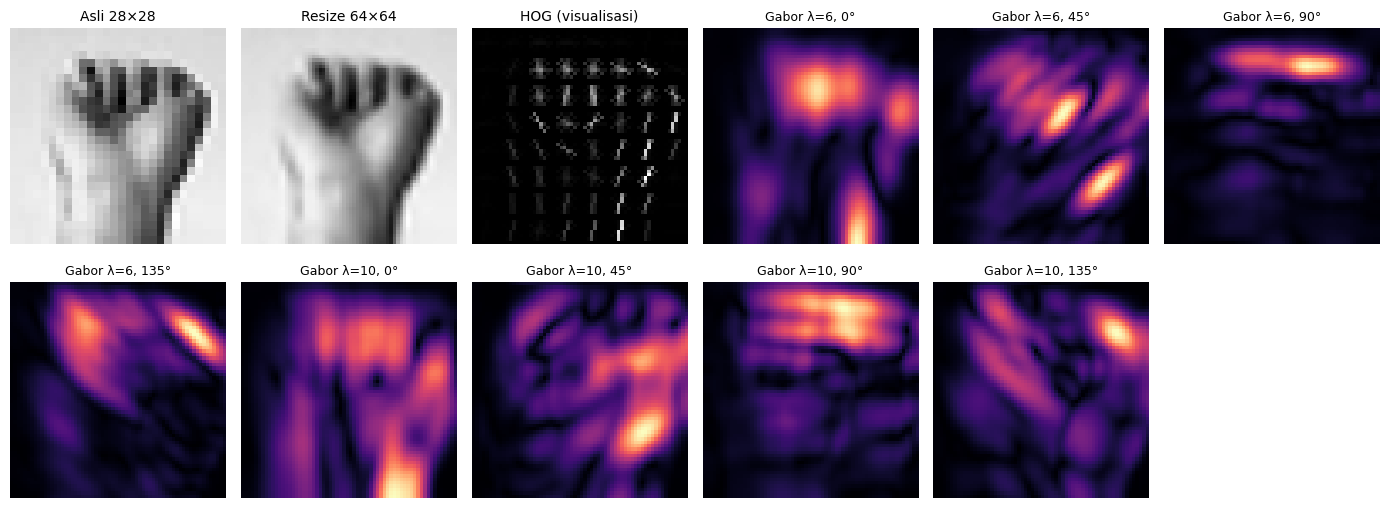

In [ ]:
def build_kernels(g):
    kernels = []
    for lam in g['wavelengths']:
        for deg in g['orientations_deg']:
            th, sigma = np.deg2rad(deg), g['sigma_ratio'] * lam
            kr = cv2.getGaborKernel((g['ksize'], g['ksize']), sigma, th, lam, g['gamma'], 0.0, ktype=cv2.CV_32F)
            ki = cv2.getGaborKernel((g['ksize'], g['ksize']), sigma, th, lam, g['gamma'], np.pi / 2, ktype=cv2.CV_32F)
            kernels.append((kr - kr.mean(), ki - ki.mean()))
    return kernels

def gabor_energy_maps(f, kernels):
    f0 = f - f.mean()
    maps = []
    for kr, ki in kernels:
        re = cv2.filter2D(f0, cv2.CV_32F, kr, borderType=cv2.BORDER_REFLECT)
        im = cv2.filter2D(f0, cv2.CV_32F, ki, borderType=cv2.BORDER_REFLECT)
        maps.append(np.sqrt(re * re + im * im))
    return maps

def one_feature(img28, cfg, kernels):
    s = cfg['image_size']
    f = cv2.resize(img28, (s, s), interpolation=cv2.INTER_LINEAR).astype(np.float32) / 255.0
    h = hog(f, orientations=cfg['hog']['orientations'], pixels_per_cell=cfg['hog']['pixels_per_cell'],
            cells_per_block=cfg['hog']['cells_per_block'], block_norm=cfg['hog']['block_norm'],
            transform_sqrt=cfg['hog']['transform_sqrt'], feature_vector=True)
    gr = cfg['gabor']['grid']
    g = np.concatenate([cv2.resize(m, (gr, gr), interpolation=cv2.INTER_AREA).ravel()
                        for m in gabor_energy_maps(f, kernels)])
    return np.concatenate([h, g]).astype(np.float32)

def _extract_chunk(chunk, cfg):
    kernels = build_kernels(cfg['gabor'])
    return np.stack([one_feature(x, cfg, kernels) for x in chunk])

FEAT_CFG = {'image_size': CONFIG['image_size'], 'hog': CONFIG['hog'], 'gabor': CONFIG['gabor']}

def extract_many(X28, desc='fitur'):
    parts = np.array_split(np.arange(len(X28)), int(max(1, min(48, len(X28) // 400 + 1))))
    res = joblib.Parallel(n_jobs=-1)(joblib.delayed(_extract_chunk)(X28[p], FEAT_CFG) for p in tqdm(parts, desc=desc))
    return np.vstack(res)

def cached_features(tag, X28, extra=''):
    X28 = np.ascontiguousarray(X28)
    key = hashlib.md5((json.dumps(FEAT_CFG, sort_keys=True, default=str) + extra).encode() + X28.tobytes()).hexdigest()[:16]
    path = CACHE / f'feat_{tag}_{key}.npy'
    if CONFIG['cache_features'] and path.exists():
        try:
            arr = np.load(path)
            if arr.shape[0] == len(X28):
                print(f'[{tag}] memakai cache fitur'); return arr
        except Exception:
            pass
    arr = extract_many(X28, desc=tag)
    if CONFIG['cache_features']:
        np.save(path, arr)
    return arr

t0 = time.time()
F_all = cached_features('train', X_all)
F_tr, F_va = F_all[tr_idx], F_all[va_idx]
N_FEATURES = F_all.shape[1]
print(f'Fitur train+validation: {F_all.shape} (HOG 1764 + Gabor 128 = {N_FEATURES}) dalam {time.time() - t0:.0f} detik')

# Gambar ilustrasi alur fitur untuk laporan
demo = X_all[int(np.where(y_all == CLASS_IDS[0])[0][0])]
s = CONFIG['image_size']
demo_f = cv2.resize(demo, (s, s), interpolation=cv2.INTER_LINEAR).astype(np.float32) / 255.0
_, hog_img = hog(demo_f, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm='L2-Hys',
                 transform_sqrt=True, visualize=True)
kers = build_kernels(CONFIG['gabor'])
gmaps = gabor_energy_maps(demo_f, kers)
fig, axs = plt.subplots(2, 6, figsize=(14, 5.4))
axs = axs.ravel()
for ax, (im, ttl) in zip(axs[:3], [(demo, 'Asli 28×28'), (demo_f, 'Resize 64×64'), (hog_img, 'HOG (visualisasi)')]):
    ax.imshow(im, cmap='gray'); ax.set_title(ttl, fontsize=10)
for k, m in enumerate(gmaps):
    axs[3 + k].imshow(m, cmap='magma')
    axs[3 + k].set_title(f'Gabor λ={CONFIG["gabor"]["wavelengths"][k // 4]:g}, {CONFIG["gabor"]["orientations_deg"][k % 4]}°', fontsize=9)
for ax in axs:
    ax.axis('off')
plt.tight_layout(); plt.savefig(OUT / 'gambar_alur_fitur.png', dpi=130); plt.show()

## 5. Augmentasi (hanya data latih)
Augmentasi tidak dipakai pada tujuh kandidat awal. Dua kandidat terbaik nanti dilatih ulang dengan tambahan citra hasil augmentasi sebanyak ±35% per huruf: rotasi ±10°, geser hingga 5%, skala 0,9–1,1, brightness/kontras ringan, serta blur dan noise ringan pada sebagian gambar. Tidak ada flip. Validation dan test tidak pernah diaugmentasi.

In [ ]:
def augment_image(img, rng):
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-10, 10), rng.uniform(0.9, 1.1))
    M[:, 2] += rng.uniform(-0.05, 0.05, 2) * w
    out = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT).astype(np.float32)
    out = out * rng.uniform(0.9, 1.1) + rng.uniform(-10, 10)
    if rng.random() < 0.25:
        out = cv2.GaussianBlur(out, (3, 3), 0.7)
    if rng.random() < 0.25:
        out = out + rng.normal(0, 2.0, out.shape)
    return np.clip(out, 0, 255).astype(np.uint8)

def build_augmented(X28, y, fraction, seed):
    rng = np.random.default_rng(seed)
    imgs, labels = [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        n = int(np.ceil(fraction * len(idx)))
        for i in rng.choice(idx, size=n, replace=False):
            imgs.append(augment_image(X28[i], rng)); labels.append(c)
    return np.stack(imgs), np.array(labels, dtype=np.int64)

_aug_cache = {}
def get_augmented_features():
    if 'F' not in _aug_cache:
        Xa, ya = build_augmented(X_all[tr_idx], y_tr, CONFIG['augmentation']['fraction'], SEED)
        _aug_cache['F'] = cached_features('aug', Xa, extra=f'aug{SEED}{CONFIG["augmentation"]["fraction"]}')
        _aug_cache['y'] = ya
    return _aug_cache['F'], _aug_cache['y']
print('Augmentasi siap dipanggil nanti (dihitung hanya jika dibutuhkan).')

Augmentasi siap dipanggil nanti (dihitung hanya jika dibutuhkan).


## 6. Latih dan bandingkan 7 kandidat
Semua kandidat memakai pipeline `StandardScaler → PCA → (LDA) → klasifier`.

| # | Kandidat |
|---|---|
| 1 | PCA 150 → LDA → k-NN |
| 2 | PCA 300 → LDA → k-NN |
| 3 | PCA 150 → LDA (sebagai klasifier) |
| 4 | PCA 150 (whitening) → Logistic Regression |
| 5 | PCA 300 (whitening) → Logistic Regression |
| 6 | PCA 150 → k-NN |
| 7 | PCA 150 → HistGradientBoosting |

Setiap kandidat dilaporkan dengan **akurasi, presisi, recall, dan F1 (macro)** pada validation, serta waktu latih, waktu prediksi, dan ukuran model. Pemenang dipilih dari **macro-F1**, lalu akurasi, lalu ukuran model terkecil. Kandidat yang tidak konvergen tidak boleh menang selama ada kandidat lain yang konvergen. k-NN dan LDA tidak punya proses iterasi sehingga selalu dianggap konvergen.

In [ ]:
M = CONFIG['models']
SPECS = [
    dict(key='pca150_lda_knn', name=f'PCA {M["pca_small"]} + LDA + k-NN', pca=M['pca_small'], whiten=False, lda=True, clf='knn'),
    dict(key='pca300_lda_knn', name=f'PCA {M["pca_large"]} + LDA + k-NN', pca=M['pca_large'], whiten=False, lda=True, clf='knn'),
    dict(key='pca150_lda', name=f'PCA {M["pca_small"]} + LDA (klasifier)', pca=M['pca_small'], whiten=False, lda=False, clf='lda'),
    dict(key='pca150_logreg', name=f'PCA {M["pca_small"]} + Logistic Regression', pca=M['pca_small'], whiten=True, lda=False, clf='logreg'),
    dict(key='pca300_logreg', name=f'PCA {M["pca_large"]} + Logistic Regression', pca=M['pca_large'], whiten=True, lda=False, clf='logreg'),
    dict(key='pca150_knn', name=f'PCA {M["pca_small"]} + k-NN', pca=M['pca_small'], whiten=False, lda=False, clf='knn'),
    dict(key='pca150_hgb', name=f'PCA {M["pca_small"]} + HistGradientBoosting', pca=M['pca_small'], whiten=False, lda=False, clf='hgb'),
]

def build_model(spec, n_samples, n_features):
    n_pca = int(min(spec['pca'], n_features, n_samples - 1))
    steps = [('scaler', StandardScaler()),
             ('pca', PCA(n_components=n_pca, whiten=spec['whiten'], svd_solver='randomized', random_state=SEED))]
    if spec['lda']:
        steps.append(('lda', LinearDiscriminantAnalysis(solver='svd')))
    if spec['clf'] == 'knn':
        clf = KNeighborsClassifier(n_neighbors=M['knn_k'], weights='distance', n_jobs=-1)
    elif spec['clf'] == 'logreg':
        clf = LogisticRegression(C=M['logreg_C'], max_iter=M['logreg_max_iter'])
    elif spec['clf'] == 'hgb':
        clf = HistGradientBoostingClassifier(max_iter=M['hgb_max_iter'], learning_rate=0.1, max_leaf_nodes=31,
                                             early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                                             random_state=SEED)
    else:
        clf = LinearDiscriminantAnalysis(solver='svd')
    steps.append(('clf', clf))
    return Pipeline(steps)

def metrics_of(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=CLASS_IDS, average='macro', zero_division=0)
    return {'accuracy': float(accuracy_score(y_true, y_pred)), 'precision_macro': float(p),
            'recall_macro': float(r), 'f1_macro': float(f)}

def model_bytes(model):
    buf = io.BytesIO(); joblib.dump(model, buf); return buf.getbuffer().nbytes

MODELS, ROWS = {}, []

def run_candidate(spec, Xtr, ytr, augmented):
    cid = spec['key'] + ('_aug' if augmented else '')
    print(f'TRAINING {spec["name"]}{" + augmentasi" if augmented else ""} ({len(Xtr)} contoh) ...', flush=True)
    model = build_model(spec, len(Xtr), Xtr.shape[1])
    t0 = time.time()
    with warnings.catch_warnings(record=True) as wlist:
        warnings.simplefilter('always')
        model.fit(Xtr, ytr)
    fit_s = time.time() - t0
    conv_warn = sorted({w.category.__name__ for w in wlist if 'Convergence' in w.category.__name__})
    converged = not conv_warn
    if spec['clf'] == 'logreg':
        converged = converged and int(np.max(model.named_steps['clf'].n_iter_)) < M['logreg_max_iter']
    t1 = time.time()
    pred = model.predict(F_va)
    pred_ms = (time.time() - t1) / len(F_va) * 1000
    mt = metrics_of(y_va, pred)
    size = model_bytes(model)
    MODELS[cid] = model
    row = {'id': cid, 'kandidat': spec['name'] + (' + augmentasi' if augmented else ''), 'augmentasi': augmented,
           'train_examples': len(Xtr), 'converged': converged, 'warnings': ','.join(conv_warn),
           'fit_seconds': round(fit_s, 1), **mt, 'pred_ms_per_sample': round(pred_ms, 3),
           'model_bytes': size, 'model_mb': round(size / 1e6, 1)}
    ROWS.append(row)
    print(f'   selesai {fit_s:.0f} dtk | val acc {mt["accuracy"]:.4f} | macro-F1 {mt["f1_macro"]:.4f} | {size / 1e6:.1f} MB', flush=True)
    return row

for spec in SPECS:
    run_candidate(spec, F_tr, y_tr, augmented=False)

SPEC_BY_KEY = {s['key']: s for s in SPECS}

def ranked(df):
    d = df.copy()
    d['_ok'] = d['converged'].astype(int)
    return d.sort_values(['_ok', 'f1_macro', 'accuracy', 'model_bytes'], ascending=[False, False, False, True]).drop(columns='_ok')

base_df = ranked(pd.DataFrame(ROWS))
print('\nPeringkat kandidat tanpa augmentasi (validation):')
display(base_df[['kandidat', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'fit_seconds', 'model_mb', 'converged']])

TRAINING PCA 150 + LDA + k-NN (21774 contoh) ...
   selesai 7 dtk | val acc 0.7509 | macro-F1 0.7815 | 3.4 MB
TRAINING PCA 300 + LDA + k-NN (21774 contoh) ...
   selesai 8 dtk | val acc 0.7664 | macro-F1 0.7872 | 4.6 MB
TRAINING PCA 150 + LDA (klasifier) (21774 contoh) ...
   selesai 9 dtk | val acc 0.6997 | macro-F1 0.7305 | 1.2 MB
TRAINING PCA 150 + Logistic Regression (21774 contoh) ...
   selesai 7 dtk | val acc 0.7201 | macro-F1 0.7317 | 1.2 MB
TRAINING PCA 300 + Logistic Regression (21774 contoh) ...
   selesai 10 dtk | val acc 0.7152 | macro-F1 0.7289 | 2.4 MB
TRAINING PCA 150 + k-NN (21774 contoh) ...
   selesai 6 dtk | val acc 0.7076 | macro-F1 0.7493 | 14.4 MB
TRAINING PCA 150 + HistGradientBoosting (21774 contoh) ...
   selesai 87 dtk | val acc 0.6555 | macro-F1 0.6459 | 7.7 MB

Peringkat kandidat tanpa augmentasi (validation):


,kandidat,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,model_mb,converged
1,PCA 300 + LDA + k-NN,0.766414,0.799561,0.810456,0.787240,8.4,4.6,True
0,PCA 150 + LDA + k-NN,0.750924,0.791968,0.801147,0.781546,7.3,3.4,True
5,PCA 150 + k-NN,0.707622,0.766632,0.766177,0.749274,5.9,14.4,True
3,PCA 150 + Logistic Regression,0.720120,0.741582,0.758561,0.731661,6.6,1.2,True
2,PCA 150 + LDA (klasifier),0.699701,0.745717,0.747178,0.730531,9.0,1.2,True
4,PCA 300 + Logistic Regression,0.715191,0.737824,0.758686,0.728930,10.0,2.4,True
6,PCA 150 + HistGradientBoosting,0.655518,0.666155,0.667134,0.645867,86.7,7.7,True


## 7. Uji ulang dua kandidat terbaik dengan augmentasi, lalu kunci pemenang

aug:   0%|          | 0/20 [00:00<?, ?it/s]

Citra augmentasi: 7633 | data latih + augmentasi: 29407
TRAINING PCA 300 + LDA + k-NN + augmentasi (29407 contoh) ...
   selesai 10 dtk | val acc 0.7729 | macro-F1 0.7859 | 5.4 MB
TRAINING PCA 150 + LDA + k-NN + augmentasi (29407 contoh) ...
   selesai 10 dtk | val acc 0.7773 | macro-F1 0.7967 | 4.2 MB


,kandidat,train_examples,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,pred_ms_per_sample,model_mb,converged
0,PCA 150 + LDA + k-NN + augmentasi,29407,0.777328,0.800242,0.817225,0.796684,10.2,0.183,4.2,True
1,PCA 300 + LDA + k-NN,21774,0.766414,0.799561,0.810456,0.787240,8.4,0.149,4.6,True
2,PCA 300 + LDA + k-NN + augmentasi,29407,0.772927,0.784545,0.812815,0.785943,10.4,0.206,5.4,True
3,PCA 150 + LDA + k-NN,21774,0.750924,0.791968,0.801147,0.781546,7.3,0.240,3.4,True
4,PCA 150 + k-NN,21774,0.707622,0.766632,0.766177,0.749274,5.9,0.312,14.4,True
5,PCA 150 + Logistic Regression,21774,0.720120,0.741582,0.758561,0.731661,6.6,0.023,1.2,True
6,PCA 150 + LDA (klasifier),21774,0.699701,0.745717,0.747178,0.730531,9.0,0.028,1.2,True
7,PCA 300 + Logistic Regression,21774,0.715191,0.737824,0.758686,0.728930,10.0,0.034,2.4,True
8,PCA 150 + HistGradientBoosting,21774,0.655518,0.666155,0.667134,0.645867,86.7,0.534,7.7,True



PEMENANG DIKUNCI: PCA 150 + LDA + k-NN + augmentasi
  validation: akurasi 0.7773 | macro-F1 0.7967 | ukuran 4.2 MB


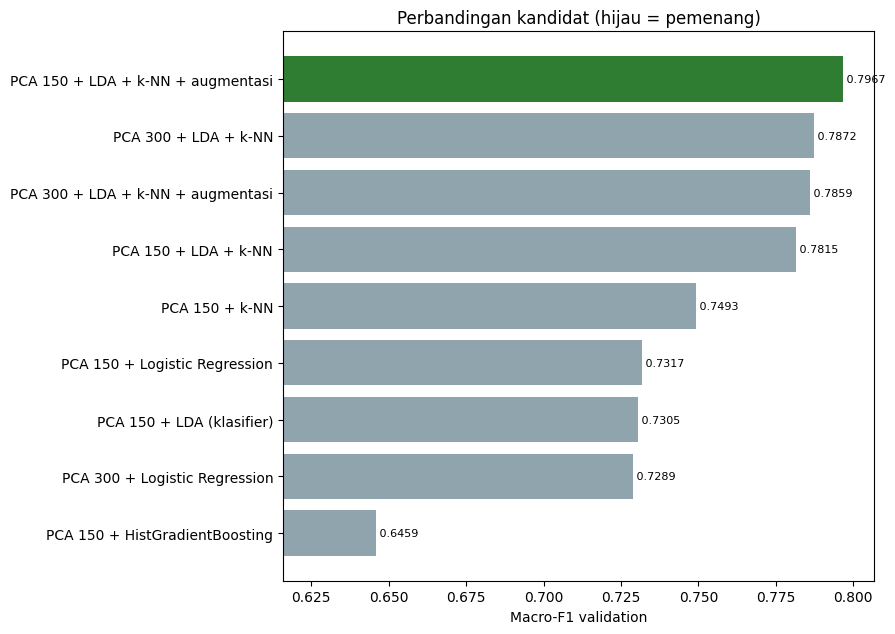

In [ ]:
top_keys = [r['id'] for _, r in base_df.head(CONFIG['augmentation']['top_k']).iterrows()]
F_aug, y_aug = get_augmented_features()
F_tr_aug, y_tr_aug = np.vstack([F_tr, F_aug]), np.concatenate([y_tr, y_aug])
N_AUG = len(y_aug)
print('Citra augmentasi:', N_AUG, '| data latih + augmentasi:', len(y_tr_aug))
for k in top_keys:
    run_candidate(SPEC_BY_KEY[k], F_tr_aug, y_tr_aug, augmented=True)

val_df = ranked(pd.DataFrame(ROWS)).reset_index(drop=True)
val_df.to_csv(OUT / 'validation_comparison.csv', index=False)
display(val_df[['kandidat', 'train_examples', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro',
                'fit_seconds', 'pred_ms_per_sample', 'model_mb', 'converged']])

WIN_ROW = val_df.iloc[0].to_dict()
WIN_ID = WIN_ROW['id']
WIN_MODEL = MODELS[WIN_ID]
WIN_SPEC = SPEC_BY_KEY[WIN_ID.replace('_aug', '')]
tie = int((np.isclose(val_df['f1_macro'], WIN_ROW['f1_macro']) & np.isclose(val_df['accuracy'], WIN_ROW['accuracy'])).sum())
print('\nPEMENANG DIKUNCI:', WIN_ROW['kandidat'])
print(f'  validation: akurasi {WIN_ROW["accuracy"]:.4f} | macro-F1 {WIN_ROW["f1_macro"]:.4f} | ukuran {WIN_ROW["model_mb"]} MB')
if tie > 1:
    print(f'  Catatan: {tie} kandidat seri pada akurasi dan macro-F1 validation, sehingga ukuran model menentukan pemenang.')

fig, ax = plt.subplots(figsize=(9, 0.55 * len(val_df) + 1.5))
order = val_df.iloc[::-1]
ax.barh(order['kandidat'], order['f1_macro'], color=['#2e7d32' if i == WIN_ID else '#90a4ae' for i in order['id']])
lo = max(0.0, float(order['f1_macro'].min()) - 0.03)
ax.set_xlim(lo, min(1.0, float(order['f1_macro'].max()) + 0.01))
ax.set_xlabel('Macro-F1 validation'); ax.set_title('Perbandingan kandidat (hijau = pemenang)')
for y_pos, v in enumerate(order['f1_macro']):
    ax.text(v, y_pos, f' {v:.4f}', va='center', fontsize=8)
plt.tight_layout(); plt.savefig(OUT / 'validation_comparison.png', dpi=130); plt.show()

## 8. Evaluasi final pada official test
Sel ini baru mengekstrak dan memprediksi official test setelah pemenang dikunci di atas. Jangan menjalankan ulang pencarian dengan tujuan mengejar skor test tertinggi, karena itu membuat test tidak lagi independen.

test:   0%|          | 0/18 [00:00<?, ?it/s]

Official test: 7172 gambar | benar 6650 | salah 522
  Akurasi          : 0.9272
  Presisi (macro)  : 0.9239
  Recall (macro)   : 0.9297
  F1-score (macro) : 0.9216
  Waktu prediksi   : 0.176 ms/gambar


,precision,recall,f1,support
A,0.9848,0.9819,0.9834,331.0
B,0.9976,0.9792,0.9883,432.0
C,1.0000,0.9935,0.9968,310.0
D,0.9655,0.9143,0.9392,245.0
E,0.9960,1.0000,0.9980,498.0
F,0.9880,1.0000,0.9940,247.0
G,0.9355,0.9167,0.9260,348.0
H,1.0000,0.9472,0.9729,436.0
I,0.8938,0.9931,0.9408,288.0
K,0.9841,0.7462,0.8488,331.0


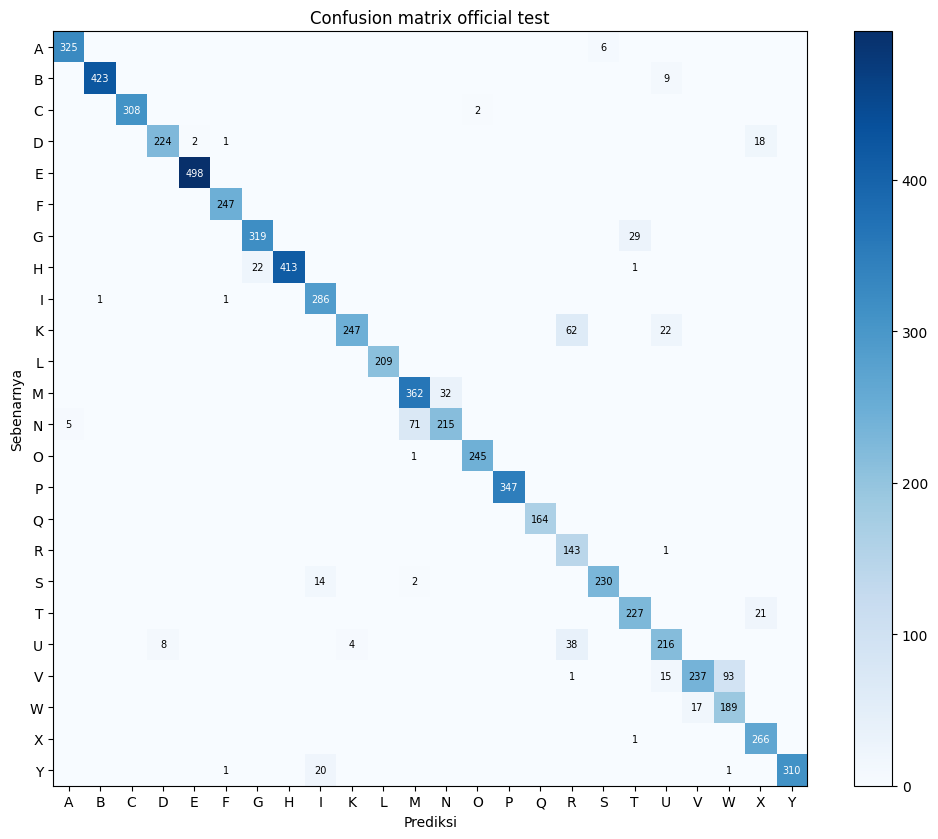

Pasangan huruf yang paling sering tertukar:


,huruf_sebenarnya,diprediksi_sebagai,jumlah
0,V,W,93
1,N,M,71
2,K,R,62
3,U,R,38
4,M,N,32
5,G,T,29
6,H,G,22
7,K,U,22
8,T,X,21
9,Y,I,20


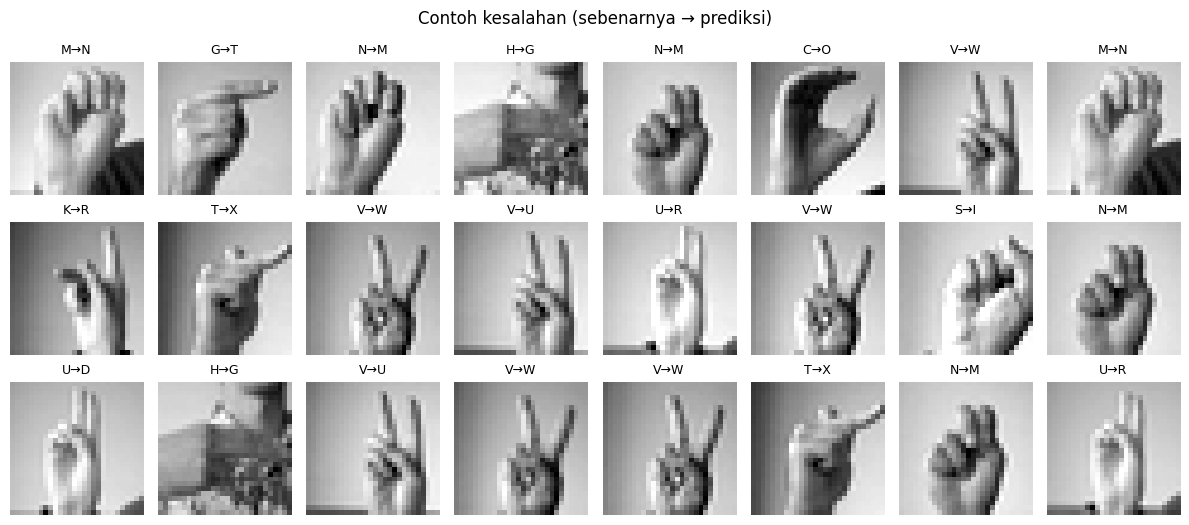

In [ ]:
F_test = cached_features('test', X_test)
t0 = time.time()
pred_test = WIN_MODEL.predict(F_test)
test_pred_ms = (time.time() - t0) / len(F_test) * 1000
TEST_M = metrics_of(y_test, pred_test)
N_CORRECT = int((pred_test == y_test).sum()); N_WRONG = N_TEST - N_CORRECT

print(f'Official test: {N_TEST} gambar | benar {N_CORRECT} | salah {N_WRONG}')
print(f'  Akurasi          : {TEST_M["accuracy"]:.4f}')
print(f'  Presisi (macro)  : {TEST_M["precision_macro"]:.4f}')
print(f'  Recall (macro)   : {TEST_M["recall_macro"]:.4f}')
print(f'  F1-score (macro) : {TEST_M["f1_macro"]:.4f}')
print(f'  Waktu prediksi   : {test_pred_ms:.3f} ms/gambar')

letter_of = {int(c): l for c, l in zip(CLASS_IDS, LETTERS)}
pd.DataFrame({'index': np.arange(N_TEST), 'true': [letter_of[int(v)] for v in y_test],
              'pred': [letter_of[int(v)] for v in pred_test], 'correct': pred_test == y_test}
             ).to_csv(OUT / 'official_test_predictions.csv', index=False)

rep = classification_report(y_test, pred_test, labels=CLASS_IDS, target_names=LETTERS, output_dict=True, zero_division=0)
per_class = pd.DataFrame(rep).T.loc[LETTERS].rename(columns={'f1-score': 'f1'})
per_class.to_csv(OUT / 'official_test_per_class.csv')
display(per_class.round(4))

cm = confusion_matrix(y_test, pred_test, labels=CLASS_IDS)
np.savetxt(OUT / 'official_test_confusion_matrix.csv', cm, fmt='%d', delimiter=',', header=','.join(LETTERS), comments='')
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(LETTERS))); ax.set_xticklabels(LETTERS); ax.set_yticks(range(len(LETTERS))); ax.set_yticklabels(LETTERS)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya'); ax.set_title('Confusion matrix official test')
thr = cm.max() / 2 if cm.max() else 1
for i in range(len(LETTERS)):
    for j in range(len(LETTERS)):
        if cm[i, j]:
            ax.text(j, i, int(cm[i, j]), ha='center', va='center', fontsize=7, color='white' if cm[i, j] > thr else 'black')
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(OUT / 'official_test_confusion_matrix.png', dpi=130); plt.show()

pairs = sorted([(LETTERS[i], LETTERS[j], int(cm[i, j])) for i in range(len(LETTERS)) for j in range(len(LETTERS))
                if i != j and cm[i, j] > 0], key=lambda t: -t[2])
top_conf = pd.DataFrame(pairs[:15], columns=['huruf_sebenarnya', 'diprediksi_sebagai', 'jumlah'])
top_conf.to_csv(OUT / 'official_test_top_confusions.csv', index=False)
print('Pasangan huruf yang paling sering tertukar:')
display(top_conf)

wrong_idx = np.where(pred_test != y_test)[0]
if len(wrong_idx):
    pick = np.random.default_rng(SEED).choice(wrong_idx, size=min(24, len(wrong_idx)), replace=False)
    cols = 8; rows_n = int(np.ceil(len(pick) / cols))
    fig, axs = plt.subplots(rows_n, cols, figsize=(cols * 1.5, rows_n * 1.8))
    for ax in np.atleast_1d(axs).ravel():
        ax.axis('off')
    for ax, i in zip(np.atleast_1d(axs).ravel(), pick):
        ax.imshow(X_test[i], cmap='gray'); ax.set_title(f'{letter_of[int(y_test[i])]}→{letter_of[int(pred_test[i])]}', fontsize=9)
    plt.suptitle('Contoh kesalahan (sebenarnya → prediksi)'); plt.tight_layout()
    plt.savefig(OUT / 'official_test_contoh_kesalahan.png', dpi=130); plt.show()

## 9. Simpan laporan dan unduh satu ZIP
Isi ZIP: model terpilih (`.joblib`), konfigurasi, tabel validation (akurasi/presisi/recall/F1 tiap kandidat), prediksi test, metrik per huruf, confusion matrix, gambar alur fitur, `LAPORAN_HASIL.html`, dan **`ringkasan_untuk_laporan.md`** yang berisi angka siap tempel ke laporan Word.

In [ ]:
def pct(x):
    return f'{x * 100:.2f}%'.replace('.', ',')

def idn(n):
    return f'{int(n):,}'.replace(',', '.')

joblib.dump({'pipeline': WIN_MODEL, 'class_ids': CLASS_IDS, 'letters': LETTERS, 'config': CONFIG,
             'winner': WIN_ROW['kandidat']}, OUT / 'model_terpilih.joblib', compress=3)
final = {
    'winner': WIN_ROW['kandidat'], 'winner_id': WIN_ID,
    'dataset': {'train_file': N_TRAIN_FILE, 'dihapus_identik_dengan_test': N_REMOVED_DUP, 'dipakai': int(len(X_all)),
                'latih': N_TR, 'validation': N_VA, 'augmentasi_tambahan': int(N_AUG), 'official_test': N_TEST,
                'kelompok_visual': int(len(np.unique(GROUPS)))},
    'fitur': {'dimensi': int(N_FEATURES), 'hog': 1764, 'gabor': 128},
    'validation_pemenang': {k: WIN_ROW[k] for k in ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']},
    'official_test': {**TEST_M, 'benar': N_CORRECT, 'salah': N_WRONG, 'pred_ms_per_sample': round(test_pred_ms, 3)},
    'model_bytes': int(WIN_ROW['model_bytes']), 'fit_seconds': WIN_ROW['fit_seconds'],
    'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'sklearn': sklearn.__version__,
                 'skimage': skimage.__version__, 'opencv': cv2.__version__},
}
(OUT / 'final_metrics.json').write_text(json.dumps(final, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
(OUT / 'config.json').write_text(json.dumps(CONFIG, indent=2, ensure_ascii=False, default=str), encoding='utf-8')

tbl = val_df[['kandidat', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro']]
md_lines = [
    '# Ringkasan untuk laporan', '',
    f'**Metode terpilih:** {WIN_ROW["kandidat"]}', '',
    '## Dataset dan pembagian',
    f'- Sign Language MNIST: berkas train {idn(N_TRAIN_FILE)} citra, official test {idn(N_TEST)} citra, {len(CLASS_IDS)} kelas ({"".join(LETTERS)}).',
    f'- Citra train identik dengan test yang dikeluarkan: {idn(N_REMOVED_DUP)}. Train dipakai: {idn(len(X_all))}.',
    f'- Pembagian ±80:20 dengan KMeans kelompok visual + StratifiedGroupKFold: latih {idn(N_TR)}, validation {idn(N_VA)}.',
    f'- Augmentasi (hanya data latih, kandidat terbaik): +{idn(N_AUG)} citra.',
    '', '## Fitur',
    f'- HOG 1.764 + Gabor 128 = {idn(N_FEATURES)} fitur per citra (gambar 64×64).', '',
    '## Tabel validation (macro untuk presisi, recall, F1)', '',
    '| Model | Akurasi | Presisi | Recall | F1-Score |', '|---|---|---|---|---|',
] + [f'| {r.kandidat} | {pct(r.accuracy)} | {pct(r.precision_macro)} | {pct(r.recall_macro)} | {pct(r.f1_macro)} |'
     for r in tbl.itertuples()] + [
    '', '## Official test (model pemenang)',
    f'- {idn(N_CORRECT)} benar, {idn(N_WRONG)} salah dari {idn(N_TEST)} citra.',
    f'- Akurasi {pct(TEST_M["accuracy"])} | Presisi {pct(TEST_M["precision_macro"])} | Recall {pct(TEST_M["recall_macro"])} | F1 {pct(TEST_M["f1_macro"])}.',
    f'- Ukuran model {idn(WIN_ROW["model_bytes"])} byte, waktu latih ±{WIN_ROW["fit_seconds"]} detik, prediksi ±{test_pred_ms:.2f} ms per citra.',
    '', '## Pasangan huruf paling sering tertukar',
] + [f'- {a} diprediksi {b}: {n} kali' for a, b, n in pairs[:8]] + [
    '', '## Catatan jujur',
    '- Kelompok visual dibuat dengan KMeans (heuristik), bukan identitas sumber foto. Validation masih bisa lebih optimistis daripada test.',
    '- Hasil belum membuktikan akurasi pada foto kamera nyata. Huruf J dan Z tidak termasuk.',
]
(OUT / 'ringkasan_untuk_laporan.md').write_text('\n'.join(md_lines), encoding='utf-8')

ERR_IMG = '<h2>Contoh kesalahan</h2><img src="official_test_contoh_kesalahan.png">' if (OUT / 'official_test_contoh_kesalahan.png').exists() else '<p>Tidak ada kesalahan pada official test.</p>'

def _fmt(df):
    return df.to_html(index=False, float_format=lambda v: f'{v:.4f}', border=0)
html = f"""<!doctype html><html lang="id"><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Laporan HOG + Gabor + PCA + LDA + kNN</title>
<style>body{{font:16px system-ui;max-width:1100px;margin:24px auto;padding:16px;line-height:1.6}}img{{max-width:100%}}
table{{border-collapse:collapse;font-size:14px}}td,th{{border:1px solid #aaa;padding:5px 8px;text-align:left}}</style>
<h1>Hasil training ASL 24 huruf</h1><p>Pemenang: <b>{WIN_ROW['kandidat']}</b></p>
<h2>Official test</h2><p>{N_CORRECT} benar dan {N_WRONG} salah dari {N_TEST} citra. Akurasi {pct(TEST_M['accuracy'])}, presisi macro {pct(TEST_M['precision_macro'])},
recall macro {pct(TEST_M['recall_macro'])}, F1 macro {pct(TEST_M['f1_macro'])}.</p>
<h2>Perbandingan validation</h2>{_fmt(val_df[['kandidat','train_examples','accuracy','precision_macro','recall_macro','f1_macro','fit_seconds','model_mb','converged']])}
<img src="validation_comparison.png"><h2>Confusion matrix</h2><img src="official_test_confusion_matrix.png">
<h2>Pasangan huruf tertukar</h2>{_fmt(top_conf)}<h2>Metrik per huruf</h2>{per_class.round(4).to_html(border=0)}
<h2>Alur fitur</h2><img src="gambar_alur_fitur.png">{ERR_IMG}
<h2>Catatan</h2><p>Kelompok visual dibuat dengan KMeans (heuristik). Hasil ini belum membuktikan akurasi kamera nyata. J dan Z tidak termasuk.</p></html>"""
(OUT / 'LAPORAN_HASIL.html').write_text(html, encoding='utf-8')

zip_path = ROOT / 'runs' / f'{CONFIG["run_name"]}_hasil.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(OUT.rglob('*')):
        if p.is_file():
            zf.write(p, p.relative_to(OUT))
print('ZIP tersimpan di:', zip_path)
print('\n' + '\n'.join(md_lines[:12]))
if IN_COLAB:
    from google.colab import files
    try:
        files.download(str(zip_path))
    except Exception as e:
        print('Unduhan browser belum berhasil:', e, '\nUnduh manual dari Drive:', zip_path)

ZIP tersimpan di: /content/drive/MyDrive/ASL_HOG_Gabor_PCA/runs/hog_gabor_pca_lda_knn_v1_hasil.zip

# Ringkasan untuk laporan

**Metode terpilih:** PCA 150 + LDA + k-NN + augmentasi

## Dataset dan pembagian
- Sign Language MNIST: berkas train 27.455 citra, official test 7.172 citra, 24 kelas (ABCDEFGHIKLMNOPQRSTUVWXY).
- Citra train identik dengan test yang dikeluarkan: 0. Train dipakai: 27.455.
- Pembagian ±80:20 dengan KMeans kelompok visual + StratifiedGroupKFold: latih 21.774, validation 5.681.
- Augmentasi (hanya data latih, kandidat terbaik): +7.633 citra.

## Fitur
- HOG 1.764 + Gabor 128 = 1.892 fitur per citra (gambar 64×64).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>